# 09: Attention weights of the CNN-BiLSTM-Attention network

Where does the attention layer look? The network (v2: log-scaled inputs plus a port embedding, see notebook 05b) reads the 60 flow features as a sequence of 60 steps, and the attention layer scores each step before pooling. This notebook extracts those weights for a class-stratified sample of the **group-split test set** and compares them with the SHAP importance of the XGBoost model (notebook 08).

Attention weights show where the pooling layer looked. They are not a causal attribution: a step holds a feature after the convolutions and the BiLSTM have mixed it with its neighbors.

In [1]:
import sys, json
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr

from src.explainability.attention import load_network, attention_weights
from src.explainability.shap_global import stratified_sample

ROOT = Path("..").resolve()
FIGS, REPORTS = ROOT / "reports" / "figures", ROOT / "reports"
features = json.loads((REPORTS / "final_features.json").read_text())["features"]
classes = list(json.loads((REPORTS / "label_encoding.json").read_text()))

In [2]:
data = pd.read_parquet(ROOT / "data/processed/training_sample.parquet", columns=features + ["Label_Encoded", "split_group"])
test = data[data["split_group"].eq("test")].reset_index(drop=True)
rows = stratified_sample(test["Label_Encoded"].to_numpy(), 300)      # same flows as notebook 08
X, y = test.loc[rows, features], test.loc[rows, "Label_Encoded"].to_numpy()

preprocessor = joblib.load(ROOT / "saved_models" / "hybrid_v2_preprocessor_group.joblib")
Z = preprocessor.transform(X)                                        # {"flow": (rows, 60, 1), "ports": (rows, 2)}
network = load_network(ROOT / "saved_models" / "cnn_bilstm_attention_v2_group.keras")
weights = attention_weights(network, Z)                              # (rows, 60 steps)
accuracy = float((network.predict(Z, verbose=0).argmax(1) == y).mean())
print(f"{len(X):,} flows, sample accuracy {accuracy:.3f}; weights sum to 1: {np.allclose(weights.sum(1), 1, atol=1e-4)}")

3,900 flows, sample accuracy 0.752; weights sum to 1: True


## How focused is the attention?
A uniform attention would give every step 1/60 = 0.017. The entropy of the weights is compared with the maximum possible (log 60).

In [3]:
entropy = -(weights * np.log(weights + 1e-12)).sum(1)
print(f"mean largest weight: {weights.max(1).mean():.3f}  (uniform: {1/60:.3f})")
print(f"mean entropy: {entropy.mean():.2f} of a possible {np.log(60):.2f}")

mean largest weight: 0.047  (uniform: 0.017)
mean entropy: 3.86 of a possible 4.09


## Attention per class
Mean attention weight per step, labeled by the feature that enters at that step, for the 15 steps with the highest average weight.

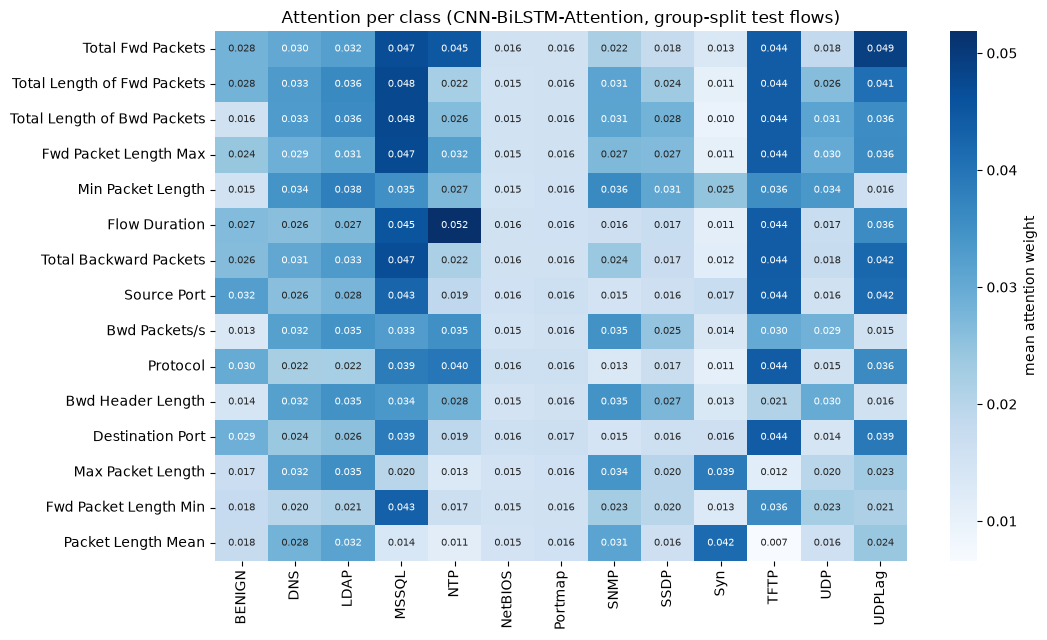

In [4]:
by_class = pd.DataFrame(weights, columns=features).groupby(y).mean()
by_class.index = classes
by_class.T.assign(**{"all classes": by_class.mean()}).sort_values("all classes", ascending=False).round(5).to_csv(REPORTS / "attention_by_class_hybrid_group.csv")  # v2 network
top = by_class.mean().sort_values(ascending=False).head(15).index
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(by_class[top].T, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "mean attention weight"}, annot_kws={"size": 7}, ax=ax)
ax.set_title("Attention per class (CNN-BiLSTM-Attention, group-split test flows)")
fig.tight_layout(); fig.savefig(FIGS / "attention_class_feature_heatmap.png", dpi=150); plt.show()

## Attention across the feature sequence
The sequence follows the feature order of the input, so neighboring steps are neighboring columns.

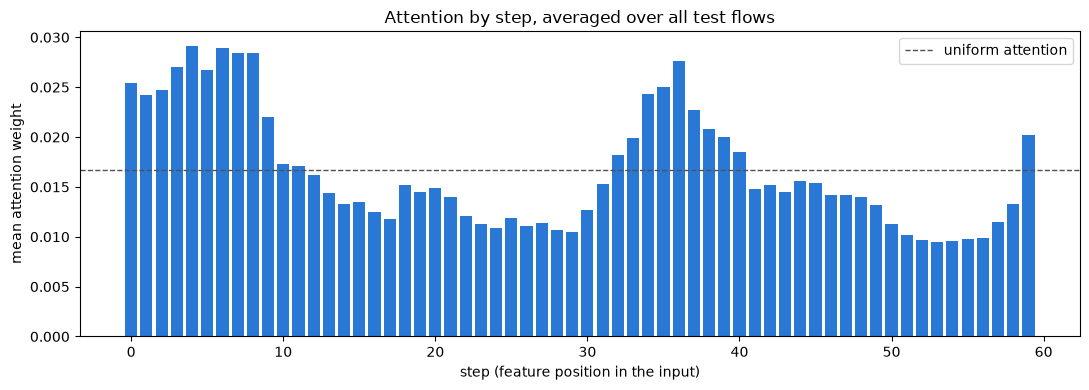

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(features)), by_class.mean().values, color="#2a78d6")
ax.axhline(1 / 60, color="#52514e", linestyle="--", linewidth=1, label="uniform attention")
ax.set_xlabel("step (feature position in the input)"); ax.set_ylabel("mean attention weight")
ax.set_title("Attention by step, averaged over all test flows"); ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "attention_by_step.png", dpi=150); plt.show()

## Does attention agree with SHAP?
Rank correlation between the network's attention and the XGBoost model's mean absolute SHAP value, over the 60 features, overall and per class.

In [6]:
shap_table = pd.read_csv(REPORTS / "shap_importance_xgboost_group.csv", index_col=0).loc[features]
rows_out = [{"class": "all classes", "spearman": spearmanr(by_class.mean(), shap_table["all classes"])[0]}]
rows_out += [{"class": c, "spearman": spearmanr(by_class.loc[c], shap_table[c])[0]} for c in classes]
agreement = pd.DataFrame(rows_out).round(2)
agreement.to_csv(REPORTS / "attention_vs_shap.csv", index=False)
print(agreement.to_string(index=False))

      class  spearman
all classes      0.41
     BENIGN      0.36
        DNS      0.39
       LDAP      0.32
      MSSQL      0.40
        NTP      0.44
    NetBIOS      0.02
    Portmap      0.10
       SNMP      0.27
       SSDP      0.32
        Syn      0.01
       TFTP      0.50
        UDP      0.30
     UDPLag      0.22
